# Reef Point Classifier — v3

CoralscapesV2 point classification with held-out sites. Predicts live coral genera, other live coral and selected background categories; it does not estimate whole-image coral cover or detect unknown categories.

Corrections: explicit live-label mapping, separate site-held-out calibration data, calibration on uniform eligible points, complete configuration fingerprints, immutable class lists in bootstrap metrics, and conservative review fallback. This notebook has been statically checked; train and validate it in Colab before deployment.


## 1. Install dependencies

In [ ]:
%pip -q install datasets huggingface_hub scikit-learn pandas matplotlib pillow tqdm scipy

## 2. Imports and settings

In [ ]:
import os, json, random, hashlib, re
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from scipy.spatial import cKDTree
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms

SEED = 42
DATASET_ID = "josauder/coralscapesV2"
MAX_IMAGES = None                 # set e.g. 200 for a quick trial run
SAMPLING_VERSION = "v3"
DATASET_REVISION = "main"  # use a commit hash to pin the dataset for a published experiment

CROP_SIZE = 224
EDGE_MARGIN = CROP_SIZE // 2      # points closer to the border than this are not sampled
BALANCED_POINTS_PER_CLASS = 2     # class-balanced points per image (train / val)
UNIFORM_POINTS_PER_IMAGE = 6      # uniform random points per image (realistic test distribution)
COLOR_TOLERANCE = 8               # max RGB distance when matching RGB masks to the official palette

MIN_TRAIN_POINTS = 100            # per class, balanced points in train
MIN_EVAL_POINTS = 20              # per class, balanced points in val and in test
VAL_FRAC, CAL_FRAC, TEST_FRAC = 0.15, 0.15, 0.20  # fractions of images, assigned by whole sites (train ≈ 50%)
SPLIT_ATTEMPTS = 300

EPOCHS = 8
PATIENCE = 3
BATCH_SIZE = 32
NUM_WORKERS = 2
LR_BACKBONE, LR_HEAD = 1e-4, 1e-3

MIN_CAL_POINTS = 100
REVIEW_TARGET_ACCURACY = 0.90
MIN_REVIEW_COVERAGE = 0.10
BOOTSTRAP_ROUNDS = 500

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/CoralscapesV2_Project")
except ImportError:
    ROOT = Path.cwd() / "CoralscapesV2_Project"

CACHE_DIR = ROOT / "cache"
PATCH_DIR = ROOT / "point_crops"
RESULTS_DIR = ROOT / "results"
for path in [CACHE_DIR, PATCH_DIR, RESULTS_DIR]:
    path.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Device: cuda
GPU: NVIDIA L4


## 3. Load the public dataset

In [ ]:
# The instances configuration includes image, label mask, site, and stem.
ds = load_dataset(DATASET_ID, "instances", cache_dir=str(CACHE_DIR), revision=DATASET_REVISION)
print(ds)
first = ds[list(ds.keys())[0]][0]
print("Columns:", ds[list(ds.keys())[0]].column_names)
print("Example site/stem:", first["site"], first["stem"])
print("Image size:", first["image"].size, "| mask size:", first["label"].size, "| mask mode:", first["label"].mode)

README.md:   0%|          | 0.00/14.6k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'instance_ids', 'stem', 'site'],
        num_rows: 1790
    })
    validation: Dataset({
        features: ['image', 'label', 'instance_ids', 'stem', 'site'],
        num_rows: 170
    })
    test: Dataset({
        features: ['image', 'label', 'instance_ids', 'stem', 'site'],
        num_rows: 473
    })
})
Columns: ['image', 'label', 'instance_ids', 'stem', 'site']
Example site/stem: site10 site10_000001_012400
Image size: (2048, 1024) | mask size: (2048, 1024) | mask mode: L


## 4. Read the official label metadata

In [ ]:
id2label_path = hf_hub_download(DATASET_ID, "id2label.json", repo_type="dataset", cache_dir=str(CACHE_DIR), revision=DATASET_REVISION)
with open(id2label_path) as f:
    raw_id2label = json.load(f)

# Accept either {id: name} or {name: id}.
if all(str(k).isdigit() for k in raw_id2label):
    id2label = {int(k): str(v).strip().lower() for k, v in raw_id2label.items()}
else:
    id2label = {int(v): str(k).strip().lower() for k, v in raw_id2label.items()}
name_to_id = {v: k for k, v in id2label.items()}


def hex_rgb(value):
    if isinstance(value, str) and value.startswith("#") and len(value) == 7:
        return tuple(int(value[i:i + 2], 16) for i in (1, 3, 5))
    if isinstance(value, (list, tuple)) and len(value) >= 3:
        return tuple(int(x) for x in value[:3])
    return None


# Colors are only needed when the label masks are RGB palette images.
color_by_id = {}
try:
    label2color_path = hf_hub_download(DATASET_ID, "label2color.json", repo_type="dataset", cache_dir=str(CACHE_DIR), revision=DATASET_REVISION)
    with open(label2color_path) as f:
        raw_label2color = json.load(f)
    for key, value in raw_label2color.items():
        color = hex_rgb(value)
        if color is None and isinstance(value, dict):
            color = hex_rgb(value.get("color") or value.get("rgb"))
        label_id = int(key) if str(key).isdigit() else name_to_id.get(str(key).strip().lower())
        if label_id is not None and color is not None:
            color_by_id[label_id] = color
except Exception as exc:
    print("label2color.json not available or not parseable:", exc)

print("Labels:", len(id2label), "| Colors:", len(color_by_id))
print("Sample labels:", list(id2label.items())[:8])

Labels: 95 | Colors: 95
Sample labels: [(1, 'acanthaster planci'), (2, 'acropora alive'), (3, 'acropora bleached'), (4, 'acropora dead'), (5, 'algae covered brain coral'), (6, 'algae covered branching coral'), (7, 'algae covered lobophylliidae'), (8, 'algae covered massive coral')]


## 5. Define conservative point labels

The mapping is rule-based. **Review the printed table and `label_mapping.csv` before trusting the results**; edit the patterns if a label lands in the wrong group.

In [ ]:
GENERA = ["acropora", "porites", "pocillopora", "stylophora", "galaxea", "pavona", "goniopora", "seriatopora"]

BACKGROUND_RE = re.compile(
    r"\b(hard substrate|human-made structure|rubble|sand|background|water column|water surface|dark|algae covered substrate)\b")
OTHER_CORAL_RE = re.compile(
    r"\b(corals?|millepora|fungiidae|lobophylliidae|xeniidae|turbinaria|nephtheidae|cirrhipathes)\b")
# Labels that mention "coral" but are not live hard/soft coral targets, or are ambiguous: leave them out.
EXCLUDE_RE = re.compile(r"\b(coralline|dead|bleached|diseased|algae|turf|cyanobacteria)\b")


def target_for(label):
    name = str(label).strip().lower()
    # Intentional background exception, evaluated before the algae exclusion.
    if name in {"hard substrate", "human-made structure", "rubble", "sand",
                "background", "water column", "water surface", "dark", "algae covered substrate"}:
        return "background"
    if EXCLUDE_RE.search(name):
        return None
    for genus in GENERA:
        if name in {genus, genus + " alive"}:
            return genus
    if OTHER_CORAL_RE.search(name):
        return "other_coral"
    # Morphology-only live labels belong to other_coral, not to an inferred genus.
    if name in {"massive alive", "meandering alive"}:
        return "other_coral"
    return None


label_to_target = {i: target_for(name) for i, name in id2label.items()}
target_names = sorted({v for v in label_to_target.values() if v is not None})
target_to_index = {name: i for i, name in enumerate(target_names)}
label_id_to_target = {i: target_to_index[v] for i, v in label_to_target.items() if v is not None}

mapping_table = pd.DataFrame({"label_id": list(id2label), "label": list(id2label.values()),
                              "target": [label_to_target[i] for i in id2label]}).sort_values(["target", "label"], na_position="last")
mapping_table.to_csv(RESULTS_DIR / "label_mapping.csv", index=False)
pd.set_option("display.max_rows", 500)
display(mapping_table)
print(mapping_table.target.fillna("UNMAPPED").value_counts())

,label_id,label,target
1,2,acropora alive,acropora
10,11,algae covered substrate,background
13,14,background,background
21,22,dark,background
37,38,hard substrate,background
39,40,human-made structure,background
67,68,rubble,background
68,69,sand,background
92,93,water column,background
93,94,water surface,background


target
UNMAPPED       62
other_coral    16
background      9
galaxea         1
acropora        1
pavona          1
goniopora       1
pocillopora     1
porites         1
seriatopora     1
stylophora      1
Name: count, dtype: int64


## 6. Create point crops

Balanced points are sampled per represented class for training and model selection. Uniform points sample only eligible labeled pixels, excluding borders; they are used for calibration and conditional test evaluation. They do **not** represent all pixels or whole-image cover. Save eligible fractions per image to make this restriction visible.


In [ ]:
if color_by_id:
    PALETTE_IDS = np.array(list(color_by_id), dtype=np.int32)
    PALETTE_TREE = cKDTree(np.array([color_by_id[i] for i in PALETTE_IDS], dtype=np.float32))
    EXACT_COLORS = {(r << 16) | (g << 8) | b: idx for idx, (r, g, b) in color_by_id.items()}

LUT_SIZE = max(max(id2label) + 1, 256)
TARGET_LUT = np.full(LUT_SIZE, -1, dtype=np.int16)
for source_id, target_id in label_id_to_target.items():
    TARGET_LUT[source_id] = target_id


def mask_to_ids(mask):
    # Class-id masks (grayscale / palette-indexed): the pixel value is the label id.
    if mask.mode in ("L", "P", "I", "I;16", "F"):
        return np.asarray(mask).astype(np.int32)
    if not color_by_id:
        raise ValueError("RGB mask found but no palette could be parsed from label2color.json.")
    arr = np.asarray(mask.convert("RGB"), dtype=np.uint8)
    packed = ((arr[..., 0].astype(np.uint32) << 16) | (arr[..., 1].astype(np.uint32) << 8) | arr[..., 2].astype(np.uint32))
    uniq, inverse = np.unique(packed.ravel(), return_inverse=True)
    mapped = np.array([EXACT_COLORS.get(int(u), -1) for u in uniq], dtype=np.int32)
    missing = np.flatnonzero(mapped < 0)
    if len(missing):
        rgb = np.stack([(uniq[missing] >> 16) & 255, (uniq[missing] >> 8) & 255, uniq[missing] & 255], axis=1).astype(np.float32)
        distance, nearest = PALETTE_TREE.query(rgb, k=1)
        mapped[missing] = np.where(distance <= COLOR_TOLERANCE, PALETTE_IDS[nearest], -1)
    return mapped[inverse].reshape(arr.shape[:2])


def ids_to_targets(ids):
    out = np.full(ids.shape, -1, dtype=np.int16)
    ok = (ids >= 0) & (ids < LUT_SIZE)
    out[ok] = TARGET_LUT[ids[ok]]
    return out


def crop_at(image, row, col, size=CROP_SIZE):
    half = size // 2
    left, top = col - half, row - half
    if left >= 0 and top >= 0 and left + size <= image.width and top + size <= image.height:
        return image.crop((left, top, left + size, top + size))
    # Near the border (only possible at inference): reflect-pad instead of black fill.
    arr = np.asarray(image.convert("RGB"))
    pad = ((max(0, -top), max(0, top + size - image.height)), (max(0, -left), max(0, left + size - image.width)), (0, 0))
    padded = np.pad(arr, pad, mode="reflect")
    t0, l0 = top + pad[0][0], left + pad[1][0]
    return Image.fromarray(padded[t0:t0 + size, l0:l0 + size])


def save_point(image, key, site, stem, target, row, col, sampling, source_split):
    patch_name = hashlib.sha1(f"{key}:{target}:{row}:{col}".encode()).hexdigest() + ".jpg"
    patch_path = PATCH_DIR / patch_name
    if not patch_path.exists():
        crop_at(image, row, col).save(patch_path, quality=92)
    return {"path": str(patch_path), "label": target, "site": site, "stem": stem, "row": row,
            "column": col, "sampling": sampling, "source_split": source_split}


SAMPLING_CONFIG = {
    "version": SAMPLING_VERSION, "dataset": DATASET_ID, "revision": DATASET_REVISION,
    "seed": SEED, "max_images": MAX_IMAGES, "crop_size": CROP_SIZE,
    "edge_margin": EDGE_MARGIN, "balanced_points": BALANCED_POINTS_PER_CLASS,
    "uniform_points": UNIFORM_POINTS_PER_IMAGE, "color_tolerance": COLOR_TOLERANCE,
    "mapping": label_to_target,
}
SAMPLING_HASH = hashlib.sha256(json.dumps(SAMPLING_CONFIG, sort_keys=True).encode()).hexdigest()[:16]
PATCH_DIR = ROOT / "point_crops" / SAMPLING_HASH
PATCH_DIR.mkdir(parents=True, exist_ok=True)
manifest_path = RESULTS_DIR / f"point_crop_manifest_{SAMPLING_HASH}.csv"
if manifest_path.exists():
    samples = pd.read_csv(manifest_path, dtype={"site": str, "stem": str})
    present = samples.path.map(os.path.exists)
    if not present.all():
        raise FileNotFoundError("Cached crops are missing. Remove this manifest and rerun sampling to rebuild it.")
    print("Reusing saved crops:", len(samples))
else:
    rng = np.random.default_rng(SEED)
    rows, seen, image_stats = [], set(), []
    n_images = n_resized = n_small = 0
    checked = False
    for split_name in ds:
        for record in tqdm(ds[split_name], desc=f"Sampling {split_name}"):
            if MAX_IMAGES and n_images >= MAX_IMAGES:
                break
            site, stem = str(record["site"]), str(record["stem"])
            key = f"{site}__{stem}"
            if key in seen:
                continue
            seen.add(key)
            image = record["image"].convert("RGB")
            mask_img = record["label"]
            if mask_img.size != image.size:
                mask_img = mask_img.resize(image.size, Image.NEAREST)
                n_resized += 1
            ids = mask_to_ids(mask_img)
            if not checked:
                known = float(np.isin(ids, list(id2label)).mean())
                print("Mask mode:", record["label"].mode, "| fraction of pixels with a known label id:", round(known, 3))
                if known < 0.20:
                    raise ValueError("Mask values do not match the official label ids/palette; inspect before training.")
                checked = True
            target_mask = ids_to_targets(ids)
            height, width = target_mask.shape
            inner = target_mask[EDGE_MARGIN:height - EDGE_MARGIN, EDGE_MARGIN:width - EDGE_MARGIN]
            if inner.size == 0:
                n_small += 1
                continue
            n_images += 1
            image_stats.append({"site": site, "stem": stem,
                                "eligible_fraction_full_image": float((target_mask >= 0).mean()),
                                "eligible_fraction_inner": float((inner >= 0).mean())})
            flat, inner_w = inner.ravel(), inner.shape[1]

            for target_index, target in enumerate(target_names):
                candidates = np.flatnonzero(flat == target_index)
                if len(candidates) == 0:
                    continue
                chosen = rng.choice(candidates, size=min(BALANCED_POINTS_PER_CLASS, len(candidates)), replace=False)
                for f in chosen:
                    row, col = int(f // inner_w) + EDGE_MARGIN, int(f % inner_w) + EDGE_MARGIN
                    rows.append(save_point(image, key, site, stem, target, row, col, "balanced", split_name))

            labeled = np.flatnonzero(flat >= 0)
            if len(labeled):
                chosen = rng.choice(labeled, size=min(UNIFORM_POINTS_PER_IMAGE, len(labeled)), replace=False)
                for f in chosen:
                    row, col = int(f // inner_w) + EDGE_MARGIN, int(f % inner_w) + EDGE_MARGIN
                    rows.append(save_point(image, key, site, stem, target_names[int(flat[f])], row, col, "uniform", split_name))
        if MAX_IMAGES and n_images >= MAX_IMAGES:
            break
    samples = pd.DataFrame(rows)
    if samples.empty:
        raise ValueError("No labeled point crops created; inspect mask values and label mapping.")
    samples.to_csv(manifest_path, index=False)
    pd.DataFrame(image_stats).to_csv(RESULTS_DIR / f"sampling_coverage_{SAMPLING_HASH}.csv", index=False)
    print(f"Images used: {n_images} | masks resized: {n_resized} | images too small: {n_small}")
    print("Saved point crops:", len(samples))

print(samples.groupby(["sampling", "label"]).size().unstack(0).fillna(0).astype(int))

Sampling train:   0%|          | 0/1790 [00:00<?, ?it/s]

Mask mode: L | fraction of pixels with a known label id: 0.933


Sampling validation:   0%|          | 0/170 [00:00<?, ?it/s]

Sampling test:   0%|          | 0/473 [00:00<?, ?it/s]

Images used: 2433 | masks resized: 0 | images too small: 0
Saved point crops: 30266
sampling     balanced  uniform
label                         
acropora         1388      283
background       4856    11132
galaxea           478       34
goniopora          90       49
other_coral      4052     1584
pavona            140       34
pocillopora      1604      319
porites          2226     1081
seriatopora        84        9
stylophora        780       43


## 7. Split by dive site

Separate sites for train, model-selection validation, confidence calibration, and final test. Assignment attempts use label support only, never model test scores. Save the selected site assignment; class restrictions make evaluation conditional on the retained taxonomy.


In [ ]:
if samples.site.nunique() < 8:
    raise ValueError("Too few distinct sites for a grouped evaluation.")


def make_assignment(frame, seed):
    rng = np.random.default_rng(seed)
    images_per_site = frame[["site", "stem"]].drop_duplicates().groupby("site").size()
    sites = images_per_site.index.to_numpy().copy()
    rng.shuffle(sites)
    total = images_per_site.sum()
    assign, got_test, got_val, got_cal = {}, 0, 0, 0
    for s in sites:
        if got_test < TEST_FRAC * total:
            assign[s] = "test"; got_test += images_per_site[s]
        elif got_val < VAL_FRAC * total:
            assign[s] = "val"; got_val += images_per_site[s]
        elif got_cal < CAL_FRAC * total:
            assign[s] = "cal"; got_cal += images_per_site[s]
        else:
            assign[s] = "train"
    return assign


def supported_classes(frame, assign):
    tmp = frame.assign(split=frame.site.map(assign))
    balanced = tmp[tmp.sampling == "balanced"]
    counts = balanced.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(["train", "val", "test"], fill_value=0)
    ok = [c for c in counts.columns
          if counts.loc["train", c] >= MIN_TRAIN_POINTS and counts.loc["val", c] >= MIN_EVAL_POINTS and counts.loc["test", c] >= MIN_EVAL_POINTS]
    return ok, counts


all_labels = set(samples.label)
best_assign, best_ok, best_attempt = None, [], -1
for attempt in range(SPLIT_ATTEMPTS):
    assign = make_assignment(samples, SEED + attempt)
    ok, _ = supported_classes(samples, assign)
    cal_count = int(((samples.site.map(assign) == "cal") & (samples.sampling == "uniform") & samples.label.isin(ok)).sum())
    if cal_count < MIN_CAL_POINTS:
        continue
    if len(ok) > len(best_ok):
        best_assign, best_ok, best_attempt = assign, ok, attempt
    if len(ok) == len(all_labels):
        break
if len(best_ok) < 3:
    raise ValueError("No site split gives at least three classes enough points in train, val and test.")

samples["split"] = samples.site.map(best_assign)
classes = sorted(best_ok)
excluded = sorted(all_labels - set(classes))
site_sets = {s: set(samples.loc[samples.split == s, "site"]) for s in ["train", "val", "cal", "test"]}
assert all(not site_sets[a] & site_sets[b] for i, a in enumerate(site_sets) for b in list(site_sets)[i + 1:])
with open(RESULTS_DIR / f"site_assignment_{SAMPLING_HASH}.json", "w") as f:
    json.dump(best_assign, f, indent=2)

print("Split attempt used:", best_attempt)
print("Sites:", {k: len(v) for k, v in site_sets.items()})
print("Images:", samples.drop_duplicates(["site", "stem"]).groupby("split").size().to_dict())
print("Kept classes:", classes)
print("EXCLUDED classes (not enough points in train/val/test):", excluded)
_, count_table = supported_classes(samples, best_assign)
print("Balanced points per split and class (all classes before filtering):")
display(count_table.T)
if len(site_sets["test"]) < 3 or len(site_sets["val"]) < 3:
    print("Warning: fewer than 3 sites in val or test; estimates will be very noisy.")

samples = samples[samples.label.isin(classes)].copy().reset_index(drop=True)
class_to_id = {name: i for i, name in enumerate(classes)}
samples["target"] = samples.label.map(class_to_id).astype(int)
if len(site_sets["cal"]) < 3:
    print("Warning: fewer than 3 calibration sites; confidence may transfer poorly.")

Split attempt used: 0
Sites: {'train': 18, 'val': 9, 'cal': 8, 'test': 6}
Images: {'cal': 426, 'test': 531, 'train': 970, 'val': 501}
Kept classes: ['acropora', 'background', 'galaxea', 'other_coral', 'pocillopora', 'porites', 'stylophora']
EXCLUDED classes (not enough points in train/val/test): ['goniopora', 'pavona', 'seriatopora']
Balanced points per split and class (all classes before filtering):


split,train,val,test
label,,,
acropora,494,200,450
background,1940,1002,1062
galaxea,316,98,22
goniopora,18,4,46
other_coral,1666,788,880
pavona,132,6,2
pocillopora,752,236,258
porites,934,684,330
seriatopora,0,42,2


## 8. Data loaders

Training and model-selection validation use balanced points. Calibration uses uniform eligible points from separate sites. Test reports balanced and uniform eligible points.


In [ ]:
MEAN = (0.485, 0.456, 0.406); STD = (0.229, 0.224, 0.225)
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=.12, contrast=.12, saturation=.08),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])


class CropDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True)
        self.tf = train_tf if training else eval_tf

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        r = self.frame.iloc[i]
        with Image.open(r.path) as im:
            x = self.tf(im.convert("RGB"))
        return x, int(r.target)


def part(split, sampling):
    return samples[(samples.split == split) & (samples.sampling == sampling)].reset_index(drop=True)


frames = {"train": part("train", "balanced"), "val": part("val", "balanced"),
          "cal": part("cal", "uniform"), "test_balanced": part("test", "balanced"), "test_uniform": part("test", "uniform")}

train_counts = frames["train"].target.value_counts()
weights = frames["train"].target.map(lambda y: 1.0 / train_counts[y]).to_numpy()
sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double), len(weights), replacement=True)

loader_args = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)
loaders = {"train": DataLoader(CropDataset(frames["train"], True), batch_size=BATCH_SIZE, sampler=sampler, **loader_args)}
for name in ["val", "cal", "test_balanced", "test_uniform"]:
    loaders[name] = DataLoader(CropDataset(frames[name]), batch_size=BATCH_SIZE * 2, shuffle=False, **loader_args)
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 6398, 'val': 3090, 'cal': 2544, 'test_balanced': 3272, 'test_uniform': 3148}


## 9. Model comparison setup

In [ ]:
def build_model(name, n, pretrained=True):
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, n)
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, n)
    elif name == "vit_b_16":
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT if pretrained else None)
        m.heads.head = nn.Linear(m.heads.head.in_features, n)
    else:
        raise ValueError(name)
    return m


def get_head(model, name):
    return {"resnet50": lambda: model.fc, "convnext_tiny": lambda: model.classifier[2], "vit_b_16": lambda: model.heads.head}[name]()


def predict_loader(model, loader):
    model.eval()
    logits, labels = [], []
    with torch.inference_mode():
        for x, y in loader:
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                z = model(x.to(DEVICE, non_blocking=True))
            logits.append(z.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


ARCHITECTURES = ["resnet50", "convnext_tiny", "vit_b_16"]
RUN_CONFIG = {"sampling_hash": SAMPLING_HASH, "site_assignment": best_assign,
              "classes": classes, "epochs": EPOCHS, "patience": PATIENCE,
              "batch_size": BATCH_SIZE, "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD,
              "weight_decay": 1e-4, "mean": MEAN, "std": STD,
              "augmentation": "flips_colorjitter_0.12_0.12_0.08", "seed": SEED,
              "torch_version": str(torch.__version__), "architectures": ARCHITECTURES}
RUN_KEY = hashlib.sha256(json.dumps(RUN_CONFIG, sort_keys=True).encode()).hexdigest()
RESULTS_DIR = RESULTS_DIR / ("run_" + RUN_KEY[:16])
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
with open(RESULTS_DIR / "run_config.json", "w") as f:
    json.dump(RUN_CONFIG, f, indent=2)
print("Models:", ARCHITECTURES)

Models: ['resnet50', 'convnext_tiny', 'vit_b_16']


## 10. Train with resumable checkpoints

Each model has its own optimizer, scheduler and gradient scaler. A checkpoint is reused only if it was created with the same classes and settings.

In [ ]:
def run_model(name):
    run_dir = RESULTS_DIR / name
    run_dir.mkdir(exist_ok=True)
    ckpt_path = run_dir / "last_checkpoint.pt"

    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = build_model(name, len(classes)).to(DEVICE)
    head_params = list(get_head(model, name).parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([{"params": backbone_params, "lr": LR_BACKBONE},
                                   {"params": head_params, "lr": LR_HEAD}], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=DEVICE.type == "cuda")
    criterion = nn.CrossEntropyLoss()
    start, best, stale, history = 0, -1.0, 0, []

    if ckpt_path.exists():
        state = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        if state.get("run_key") == RUN_KEY:
            model.load_state_dict(state["model"]); optimizer.load_state_dict(state["optimizer"])
            scheduler.load_state_dict(state["scheduler"]); scaler.load_state_dict(state["scaler"])
            start, best, stale, history = state["epoch"] + 1, state["best_f1"], state["stale"], state["history"]
            if state.get("complete"):
                print(name, "already complete"); return history
            print("Resuming", name, "at epoch", start + 1)
        else:
            print("Ignoring checkpoint from a different configuration:", name)

    def save_state(epoch, complete):
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": epoch, "best_f1": best, "stale": stale, "history": history,
                    "classes": classes, "run_key": RUN_KEY, "complete": complete}, ckpt_path)

    last_epoch = start - 1
    for epoch in range(start, EPOCHS):
        if stale >= PATIENCE:
            break
        model.train(); total = 0; loss_sum = 0.0
        for x, y in tqdm(loaders["train"], desc=f"{name} {epoch + 1}/{EPOCHS}", leave=False):
            x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total += len(y); loss_sum += loss.item() * len(y)
        scheduler.step()

        logits, yt = predict_loader(model, loaders["val"])
        yp = logits.argmax(1)
        mf1 = f1_score(yt, yp, average="macro", zero_division=0)
        row = {"epoch": epoch + 1, "train_loss": loss_sum / max(total, 1), "val_macro_f1": mf1,
               "val_balanced_accuracy": balanced_accuracy_score(yt, yp), "val_accuracy": accuracy_score(yt, yp)}
        history.append(row)
        if mf1 > best:
            best, stale = mf1, 0
            torch.save({"model": model.state_dict(), "classes": classes, "architecture": name, "run_key": RUN_KEY}, run_dir / "best_model.pt")
        else:
            stale += 1
        last_epoch = epoch
        save_state(epoch, False)
        print(f"{name} epoch {epoch + 1}: val Macro F1={mf1:.4f} | Balanced Acc={row['val_balanced_accuracy']:.4f} | Acc={row['val_accuracy']:.4f}")

    save_state(last_epoch, True)
    pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
    return history


runs = {}
for arch in ARCHITECTURES:
    runs[arch] = run_model(arch)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
print("Training comparison complete.")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 170MB/s]


resnet50 1/8:   0%|          | 0/200 [00:00<?, ?it/s]

resnet50 epoch 1: val Macro F1=0.5788 | Balanced Acc=0.6199 | Acc=0.6142


resnet50 2/8:   0%|          | 0/200 [00:00<?, ?it/s]

...

vit_b_16 epoch 6: val Macro F1=0.7357 | Balanced Acc=0.7243 | Acc=0.7560


vit_b_16 7/8:   0%|          | 0/200 [00:00<?, ?it/s]

vit_b_16 epoch 7: val Macro F1=0.7416 | Balanced Acc=0.7242 | Acc=0.7631


vit_b_16 8/8:   0%|          | 0/200 [00:00<?, ?it/s]

vit_b_16 epoch 8: val Macro F1=0.7487 | Balanced Acc=0.7215 | Acc=0.7702
Training comparison complete.


## 11. Select by validation Macro F1

In [ ]:
scores = []
for arch in ARCHITECTURES:
    h = pd.read_csv(RESULTS_DIR / arch / "history.csv")
    best_row = h.loc[h.val_macro_f1.idxmax()]
    scores.append({"architecture": arch, "best_epoch": int(best_row.epoch),
                   **{k: float(best_row[k]) for k in ["val_macro_f1", "val_balanced_accuracy", "val_accuracy"]}})
comparison = pd.DataFrame(scores).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
display(comparison)
WINNER = comparison.iloc[0].architecture
print("Selected:", WINNER)

,architecture,best_epoch,val_macro_f1,val_balanced_accuracy,val_accuracy
0,vit_b_16,8,0.748740,0.721534,0.770227
1,convnext_tiny,7,0.747115,0.728026,0.752427
2,resnet50,8,0.691680,0.687839,0.706796


Selected: vit_b_16


## 12. Calibrate confidence on separate sites

Temperature scaling and review threshold use uniform eligible points from calibration sites, separate from model-selection validation and test. Choose the threshold with maximum observed coverage meeting the target accuracy. If none meets it at minimum coverage, require review for every prediction. This empirical target is not a deployment guarantee.


In [ ]:
def load_best(arch):
    state = torch.load(RESULTS_DIR / arch / "best_model.pt", map_location=DEVICE, weights_only=False)
    if state.get("run_key") != RUN_KEY or state["classes"] != classes:
        raise ValueError("Best checkpoint does not match this experiment.")
    model = build_model(arch, len(classes), pretrained=False)
    model.load_state_dict(state["model"])
    return model.to(DEVICE).eval()


def softmax_np(logits, temperature=1.0):
    return torch.softmax(torch.from_numpy(logits).float() / temperature, dim=1).numpy()


def fit_temperature(logits, labels):
    z = torch.from_numpy(logits).float(); y = torch.from_numpy(labels).long()
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(z / log_t.exp(), y)
        loss.backward()
        return loss
    opt.step(closure)
    temperature = float(log_t.exp().item())
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature optimization failed.")
    return temperature


def expected_calibration_error(prob, y, bins=15):
    conf, pred = prob.max(1), prob.argmax(1)
    correct = pred == y
    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


winner_model = load_best(WINNER)
cal_logits, y_cal = predict_loader(winner_model, loaders["cal"])
TEMPERATURE = fit_temperature(cal_logits, y_cal)
cal_prob = softmax_np(cal_logits, TEMPERATURE)
print("Temperature:", round(TEMPERATURE, 3))
print("Calibration ECE  raw:", round(expected_calibration_error(softmax_np(cal_logits), y_cal), 4),
      "| calibrated:", round(expected_calibration_error(cal_prob, y_cal), 4))

cal_conf, cal_pred = cal_prob.max(1), cal_prob.argmax(1)
candidates = np.unique(np.quantile(cal_conf, np.linspace(0, 0.95, 96)))
table = []
for t in candidates:
    keep = cal_conf >= t
    if keep.mean() >= MIN_REVIEW_COVERAGE:
        table.append((float(t), float(keep.mean()), float(accuracy_score(y_cal[keep], cal_pred[keep]))))
reaching = [r for r in table if r[2] >= REVIEW_TARGET_ACCURACY]
if reaching:
    REVIEW_THRESHOLD, cov, acc = max(reaching, key=lambda r: r[1])
else:
    REVIEW_THRESHOLD, cov, acc = 1.01, 0.0, float("nan")
    print("Target accuracy not reached at minimum coverage: all predictions require review.")
print("Review threshold (calibrated):", round(REVIEW_THRESHOLD, 4))
print("Calibration coverage (auto-accepted):", round(cov, 3), "| accepted accuracy:", round(acc, 3))
CALIBRATION_STATUS = "target_met_on_calibration" if reaching else "review_all"
pd.DataFrame(table, columns=["threshold", "coverage", "accuracy"]).to_csv(RESULTS_DIR / "calibration_thresholds.csv", index=False)


Temperature: 1.797
Calibration ECE  raw: 0.0892 | calibrated: 0.0217
Review threshold (calibrated): 0.6782
Calibration coverage (auto-accepted): 0.81 | accepted accuracy: 0.902


## 13. Final held-out site test

The test sites are used once, for the selected model only. Reported on balanced points and on uniform random points, with per-site results and a site-level bootstrap interval.

TEST_BALANCED | points: 3272 | sites: 6
macro_f1: 0.7525
weighted_f1: 0.7781
balanced_accuracy: 0.7406
accuracy: 0.7772
ece_calibrated: 0.0362
ece_raw: 0.1263
macro_f1_ci95_by_site: [0.6777 0.7933]
              precision    recall  f1-score   support

    acropora       0.77      0.73      0.75       450
  background       0.85      0.86      0.86      1062
     galaxea       0.58      0.68      0.62        22
 other_coral       0.65      0.76      0.70       880
 pocillopora       0.87      0.78      0.82       258
     porites       0.84      0.76      0.79       330
  stylophora       0.86      0.62      0.72       270

    accuracy                           0.78      3272
   macro avg       0.77      0.74      0.75      3272
weighted avg       0.79      0.78      0.78      3272

Coral -> background: 0.07330316742081448 | Background -> coral: 0.13653483992467044


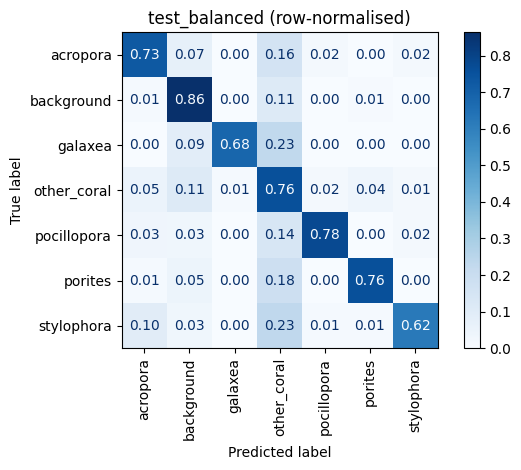

Review rate: 0.233 | accepted accuracy: 0.8604465709728868
Per-site accuracy:


,points,accuracy
site,,
site7,1294,0.725657
site13,228,0.785088
site9,1450,0.806897
site26,204,0.848039
site16,88,0.852273
site39,8,0.875000


TEST_UNIFORM | points: 3148 | sites: 6
macro_f1: 0.6493
weighted_f1: 0.8668
balanced_accuracy: 0.764
accuracy: 0.8482
ece_calibrated: 0.0184
ece_raw: 0.0744
macro_f1_ci95_by_site: [0.5045 0.6964]
              precision    recall  f1-score   support

    acropora       0.62      0.77      0.69       112
  background       0.98      0.87      0.92      2582
     galaxea       0.25      0.67      0.36         3
 other_coral       0.39      0.73      0.51       282
 pocillopora       0.67      0.84      0.74        38
     porites       0.74      0.78      0.76       118
  stylophora       0.47      0.69      0.56        13

    accuracy                           0.85      3148
   macro avg       0.59      0.76      0.65      3148
weighted avg       0.90      0.85      0.87      3148

Coral -> background: 0.0636042402826855 | Background -> coral: 0.13129357087529048


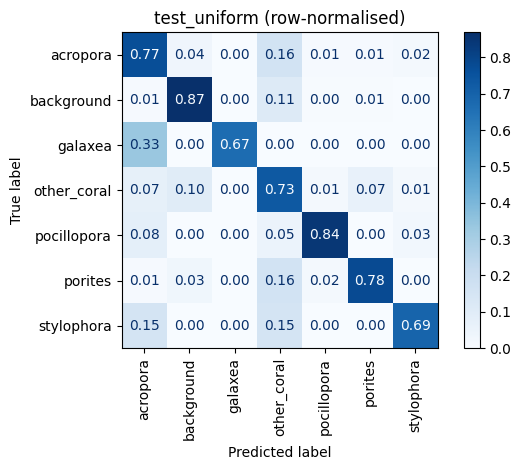

Review rate: 0.186 | accepted accuracy: 0.9161466458658346
Per-site accuracy:


,points,accuracy
site,,
site39,24,0.750000
site13,198,0.782828
site7,960,0.842708
site26,306,0.849673
site9,1504,0.857713
site16,156,0.884615


In [ ]:
def site_bootstrap(frame, y, pred, rounds=BOOTSTRAP_ROUNDS, seed=SEED):
    rng = np.random.default_rng(seed)
    site_arr = frame.site.to_numpy()
    groups = {s: np.flatnonzero(site_arr == s) for s in np.unique(site_arr)}
    keys = list(groups)
    vals = []
    for _ in range(rounds):
        pick = rng.choice(len(keys), size=len(keys), replace=True)
        idx = np.concatenate([groups[keys[i]] for i in pick])
        vals.append(f1_score(y[idx], pred[idx], labels=list(range(len(classes))), average="macro", zero_division=0))
    return np.percentile(vals, [2.5, 97.5])


def report(name):
    logits, y = predict_loader(winner_model, loaders[name])
    prob = softmax_np(logits, TEMPERATURE)
    pred = prob.argmax(1)
    frame = frames[name]
    labels = list(range(len(classes)))
    print("=" * 70); print(name.upper(), "| points:", len(y), "| sites:", frame.site.nunique())
    metrics = {"macro_f1": f1_score(y, pred, labels=labels, average="macro", zero_division=0),
               "weighted_f1": f1_score(y, pred, average="weighted", zero_division=0),
               "balanced_accuracy": balanced_accuracy_score(y, pred), "accuracy": accuracy_score(y, pred),
               "ece_calibrated": expected_calibration_error(prob, y),
               "ece_raw": expected_calibration_error(softmax_np(logits), y)}
    lo, hi = site_bootstrap(frame, y, pred)
    metrics["macro_f1_ci95_by_site"] = [float(lo), float(hi)]
    for k, v in metrics.items():
        print(f"{k}: {np.round(v, 4)}")
    print(classification_report(y, pred, labels=labels, target_names=classes, zero_division=0))

    if "background" in class_to_id:
        bg = class_to_id["background"]
        is_coral = y != bg
        if is_coral.any():
            metrics["coral_predicted_as_background"] = float((pred[is_coral] == bg).mean())
        if (~is_coral).any():
            metrics["background_predicted_as_coral"] = float((pred[~is_coral] != bg).mean())
        print("Coral -> background:", metrics.get("coral_predicted_as_background"),
              "| Background -> coral:", metrics.get("background_predicted_as_coral"))

    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=labels, normalize="true"), display_labels=classes).plot(
        xticks_rotation=90, cmap="Blues", values_format=".2f")
    plt.title(f"{name} (row-normalised)"); plt.tight_layout(); plt.show()

    accepted = prob.max(1) >= REVIEW_THRESHOLD
    metrics["review_rate"] = float((~accepted).mean())
    metrics["accepted_accuracy"] = float(accuracy_score(y[accepted], pred[accepted])) if accepted.any() else None
    print("Review rate:", round(metrics["review_rate"], 3), "| accepted accuracy:", metrics["accepted_accuracy"])

    per_site = (pd.DataFrame({"site": frame.site, "correct": (pred == y)}).groupby("site")
                .agg(points=("correct", "size"), accuracy=("correct", "mean")).sort_values("accuracy"))
    print("Per-site accuracy:"); display(per_site)
    return {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in metrics.items()}


test_metrics = {name: report(name) for name in ["test_balanced", "test_uniform"]}
with open(RESULTS_DIR / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

## 14. Save model and inference metadata

The live model stays on its device; a CPU copy of the weights is saved.

In [ ]:
EXPORT_DIR = RESULTS_DIR / "export"
EXPORT_DIR.mkdir(exist_ok=True)
cpu_state = {k: v.detach().cpu().clone() for k, v in winner_model.state_dict().items()}
torch.save({"architecture": WINNER, "state_dict": cpu_state, "classes": classes}, EXPORT_DIR / "reef_point_classifier.pt")
config = {"dataset": DATASET_ID, "architecture": WINNER, "classes": classes, "crop_size": CROP_SIZE,
          "mean": MEAN, "std": STD, "temperature": TEMPERATURE, "review_threshold": float(REVIEW_THRESHOLD),
          "task": "semantic-mask-derived point crop classification", "split_unit": "dive site",
          "seed": SEED, "excluded_low_support_classes": excluded,
          "run_key": RUN_KEY, "sampling_hash": SAMPLING_HASH, "calibration_status": CALIBRATION_STATUS,
          "evaluation_scope": "retained eligible labels, inner-image points only",
          "sites": {k: len(v) for k, v in site_sets.items()},
          "point_format": "(row, column) = (y, x) in pixels"}
with open(EXPORT_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved:", EXPORT_DIR)

Saved: /content/drive/MyDrive/CoralscapesV2_Project/results/run_b03f3ddae1699f26/export


## 15. Inference on uploaded image points

Points are `(row, column)` = `(y, x)` in pixels. Confidence is temperature-calibrated; `needs_expert_review` uses the validation-selected threshold.

In [ ]:
def load_exported(export_dir=EXPORT_DIR, device=DEVICE):
    export_dir = Path(export_dir)
    with open(export_dir / "config.json") as f:
        cfg = json.load(f)
    ckpt = torch.load(export_dir / "reef_point_classifier.pt", map_location="cpu", weights_only=True)
    model = build_model(cfg["architecture"], len(cfg["classes"]), pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(device).eval(), cfg


def predict_points(image_path, points, model, cfg, device=DEVICE):
    image = Image.open(image_path).convert("RGB")
    tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(cfg["mean"], cfg["std"])])
    crops = []
    for row, col in points:
        if not (0 <= row < image.height and 0 <= col < image.width):
            raise ValueError(f"Point outside image: {(row, col)}")
        crops.append(tf(crop_at(image, row, col, cfg["crop_size"])))
    if not crops:
        return []
    names, output = cfg["classes"], []
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(crops), 64):
            x = torch.stack(crops[start:start + 64]).to(device)
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                z = model(x).float()
            prob = torch.softmax(z / cfg["temperature"], dim=1).cpu().numpy()
            for j, p in enumerate(prob):
                top = np.argsort(p)[::-1][:3]
                row, col = points[start + j]
                output.append({"row": row, "column": col, "prediction": names[int(top[0])], "score": float(p[top[0]]),
                               "alternatives": [(names[int(k)], float(p[k])) for k in top[1:]],
                               "needs_expert_review": bool(p[top[0]] < cfg["review_threshold"])})
    return output


# Example:
# exported_model, exported_cfg = load_exported()
# result = predict_points("/content/reef_photo.jpg", [(300, 450), (700, 900)], exported_model, exported_cfg)
# pd.DataFrame(result)

In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

EXPORT_DIR = Path(
    "/content/drive/MyDrive/CoralscapesV2_Project/"
    "results/run_b03f3ddae1699f26/export"
)

for filename in ["reef_point_classifier.pt", "config.json"]:
    path = EXPORT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}")
    print(f"Found: {filename}")

print("\nReady to load the model.")

Mounted at /content/drive
Found: reef_point_classifier.pt
Found: config.json

Ready to load the model.


Model loaded: vit_b_16
Device: cuda

Upload one coral image:


Saving P5190221-2.jpg to P5190221-2.jpg


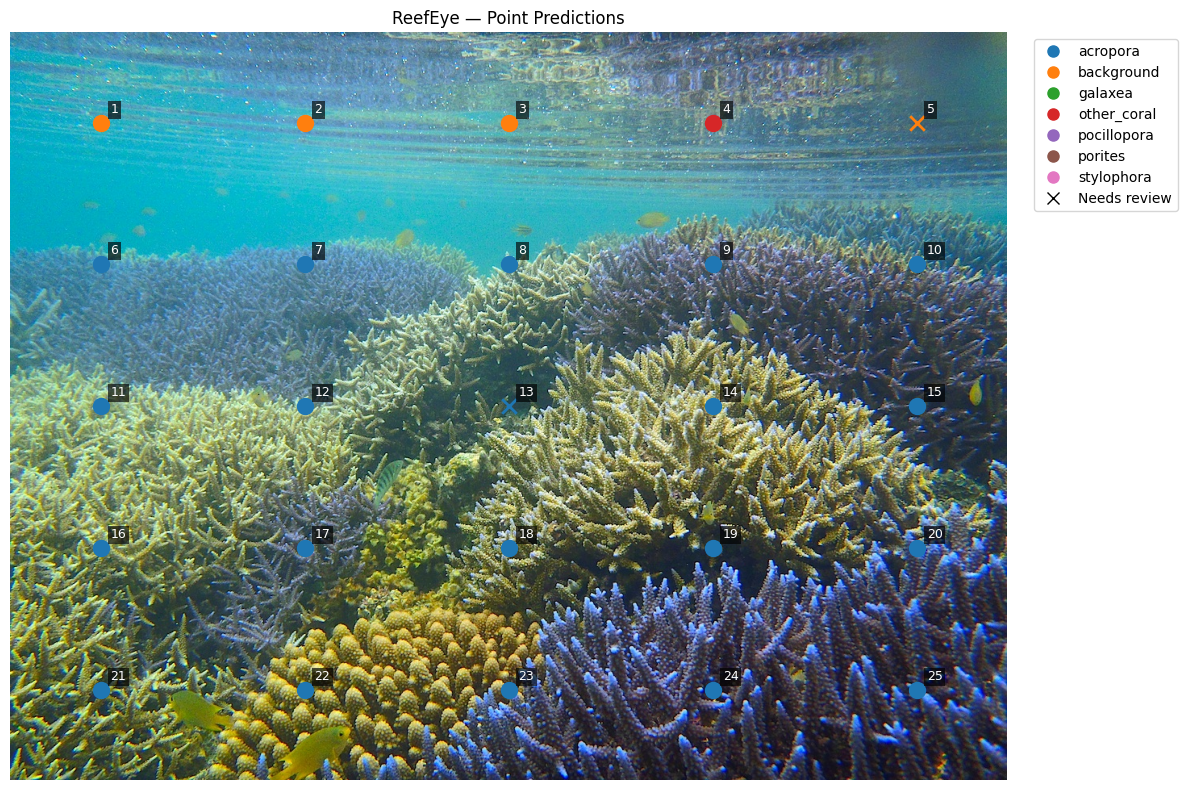

,point,row,column,prediction,confidence,needs_review
0,1,112,112,background,83.3%,False
1,2,112,365,background,85.7%,False
2,3,112,618,background,73.4%,False
3,4,112,871,other_coral,74.1%,False
4,5,112,1124,background,57.4%,True
5,6,287,112,acropora,95.0%,False
6,7,287,365,acropora,89.2%,False
7,8,287,618,acropora,76.3%,False
8,9,287,871,acropora,97.5%,False
9,10,287,1124,acropora,94.9%,False


Points: 25
Needs review: 2


In [4]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from PIL import Image, ImageOps
from torch import nn
from torchvision import models, transforms
from matplotlib.lines import Line2D
from google.colab import files
from IPython.display import display

# 1. Load the saved model
export_dir = Path(
    "/content/drive/MyDrive/CoralscapesV2_Project/"
    "results/run_b03f3ddae1699f26/export"
)

with open(export_dir / "config.json") as f:
    cfg = json.load(f)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
names = cfg["classes"]

if cfg["architecture"] != "vit_b_16":
    raise ValueError(f"Unexpected architecture: {cfg['architecture']}")

model = models.vit_b_16(weights=None)
model.heads.head = nn.Linear(model.heads.head.in_features, len(names))

checkpoint = torch.load(
    export_dir / "reef_point_classifier.pt",
    map_location="cpu",
    weights_only=True
)

if checkpoint["classes"] != names:
    raise ValueError("Model classes do not match config.json.")

model.load_state_dict(checkpoint["state_dict"])
model = model.to(device).eval()

print("Model loaded:", cfg["architecture"])
print("Device:", device)

# 2. Upload one image
print("\nUpload one coral image:")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Upload exactly one image, then rerun this cell.")

image_path = next(iter(uploaded))

with Image.open(image_path) as im:
    image = ImageOps.exif_transpose(im).convert("RGB")

# Keep the original resolution; sample points away from image borders
crop_size = int(cfg["crop_size"])
half = crop_size // 2
width, height = image.size

if width < crop_size or height < crop_size:
    raise ValueError(
        f"Image must be at least {crop_size} × {crop_size} pixels."
    )

xs = np.unique(
    np.linspace(half, width - (crop_size - half), 5).astype(int)
)
ys = np.unique(
    np.linspace(half, height - (crop_size - half), 5).astype(int)
)
points = [(int(y), int(x)) for y in ys for x in xs]

tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cfg["mean"], cfg["std"])
])

crops = [
    tf(image.crop((
        x - half,
        y - half,
        x - half + crop_size,
        y - half + crop_size
    )))
    for y, x in points
]

# 3. Predict using calibrated confidence
with torch.inference_mode():
    batch = torch.stack(crops).to(device)

    with torch.autocast(
        device_type=device.type,
        enabled=device.type == "cuda"
    ):
        logits = model(batch).float()

    probabilities = torch.softmax(
        logits / float(cfg["temperature"]), dim=1
    ).cpu().numpy()

rows = []
threshold = float(cfg["review_threshold"])

for point_id, ((y, x), prob) in enumerate(
    zip(points, probabilities), start=1
):
    predicted_id = int(prob.argmax())
    confidence = float(prob[predicted_id])

    rows.append({
        "point": point_id,
        "row": y,
        "column": x,
        "prediction": names[predicted_id],
        "confidence": confidence,
        "needs_review": confidence < threshold
    })

results = pd.DataFrame(rows)

# 4. Display predictions on the image
palette = plt.get_cmap("tab10")
colors = {name: palette(i) for i, name in enumerate(names)}

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(image)

for row in rows:
    marker = "x" if row["needs_review"] else "o"

    ax.scatter(
        row["column"], row["row"],
        color=colors[row["prediction"]],
        marker=marker,
        s=110,
        linewidths=2
    )

    ax.annotate(
        str(row["point"]),
        (row["column"], row["row"]),
        xytext=(7, 7),
        textcoords="offset points",
        color="white",
        fontsize=9,
        bbox=dict(
            facecolor="black",
            alpha=0.65,
            edgecolor="none",
            pad=2
        )
    )

legend = [
    Line2D(
        [0], [0], marker="o", linestyle="",
        color=colors[name], label=name, markersize=8
    )
    for name in names
]
legend.append(
    Line2D(
        [0], [0], marker="x", linestyle="",
        color="black", label="Needs review", markersize=8
    )
)

ax.legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("ReefEye — Point Predictions")
ax.axis("off")
plt.tight_layout()
plt.show()

display(
    results.style.format({"confidence": "{:.1%}"})
)

print(f"Points: {len(results)}")
print(f"Needs review: {int(results['needs_review'].sum())}")